### Experiment notes — 1

Introduction and motivation for the analysis. Interpretation of results and model behavior.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 2

Assignment scope and evaluation requirements. Key techniques: RMSE.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 3

Dataset overview and problem setup.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 4

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.linear_model import Ridge, Lasso, LinearRegression, RidgeCV
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate # split dataset function
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer

RANDOM_SEED = 42

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']  # Implementation note
plt.rcParams['axes.unicode_minus'] = False  # display

In [2]:
data_df = pd.read_csv('./data/cwurData.csv')  # csv file for pandas DataFrame
data_df.head(3).T  # inspect inspect

,0,1,2
world_rank,1,2,3
institution,Harvard University,Massachusetts Institute of Technology,Stanford University
region,USA,USA,USA
national_rank,1,2,3
quality_of_education,7,9,17
alumni_employment,9,17,11
quality_of_faculty,1,3,5
publications,1,12,4
influence,1,4,2
citations,1,4,2


### Experiment notes — 7

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [3]:
data_df = data_df.dropna()  # NaN row
len(data_df)

2000

### Experiment notes — 9

Interpretation of results and model behavior. Train and compare machine learning models.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [4]:
feature_cols = ['quality_of_faculty', 'publications', 'citations', 'alumni_employment', 
                'influence', 'quality_of_education', 'broad_impact', 'patents']
responder_cols = 'score'
feature_dist = 'region'
X = data_df[feature_cols]
Y = data_df[responder_cols]
X

,quality_of_faculty,publications,citations,alumni_employment,influence,quality_of_education,broad_impact,patents
200,1,1,1,1,1,1,1.0,2
201,4,5,3,2,3,11,4.0,6
202,2,15,2,11,2,3,2.0,1
203,5,10,12,10,9,2,13.0,48
204,10,11,11,12,12,7,12.0,16
...,...,...,...,...,...,...,...,...
2195,218,926,812,567,845,367,969.0,816
2196,218,997,645,566,908,236,981.0,871
2197,218,830,812,549,823,367,975.0,824
2198,218,886,812,567,974,367,975.0,651


### Experiment notes — 11

Interpretation of results and model behavior.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [5]:
print(f"📊 {len(feature_cols)} 个特征, {len([feature_dist])} 个地区离散变量，{len([responder_cols])} 个responder。")
print(f"\n✅ 总数据: {len(data_df):,} 行")

📊 8 个特征, 1 个地区离散变量，1 个responder。

✅ 总数据: 2,000 行


In [6]:
# Figure 1: statistics feature
stats_df = data_df[feature_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
print("=== 图表1: 特征统计 (百分位数) ===")
display(stats_df.round(2))

=== 图表1: 特征统计 (百分位数) ===


,quality_of_faculty,publications,citations,alumni_employment,influence,quality_of_education,broad_impact,patents
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,191.13,500.42,449.34,385.26,500.22,296.00,496.70,470.32
std,52.40,288.67,250.14,171.87,288.31,106.87,286.92,259.63
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
1%,10.99,10.99,10.99,10.99,10.99,10.99,10.00,10.99
5%,50.95,50.95,48.00,50.95,50.95,50.95,50.95,50.95
25%,210.00,250.75,234.00,250.75,250.75,250.75,250.50,242.75
50%,210.00,500.50,428.00,478.00,500.50,355.00,496.00,481.00
75%,218.00,750.00,645.00,500.25,750.25,367.00,741.00,737.00
95%,218.00,950.05,812.00,567.00,950.00,367.00,946.00,871.00


=== 图表2: 特征分布图 ===


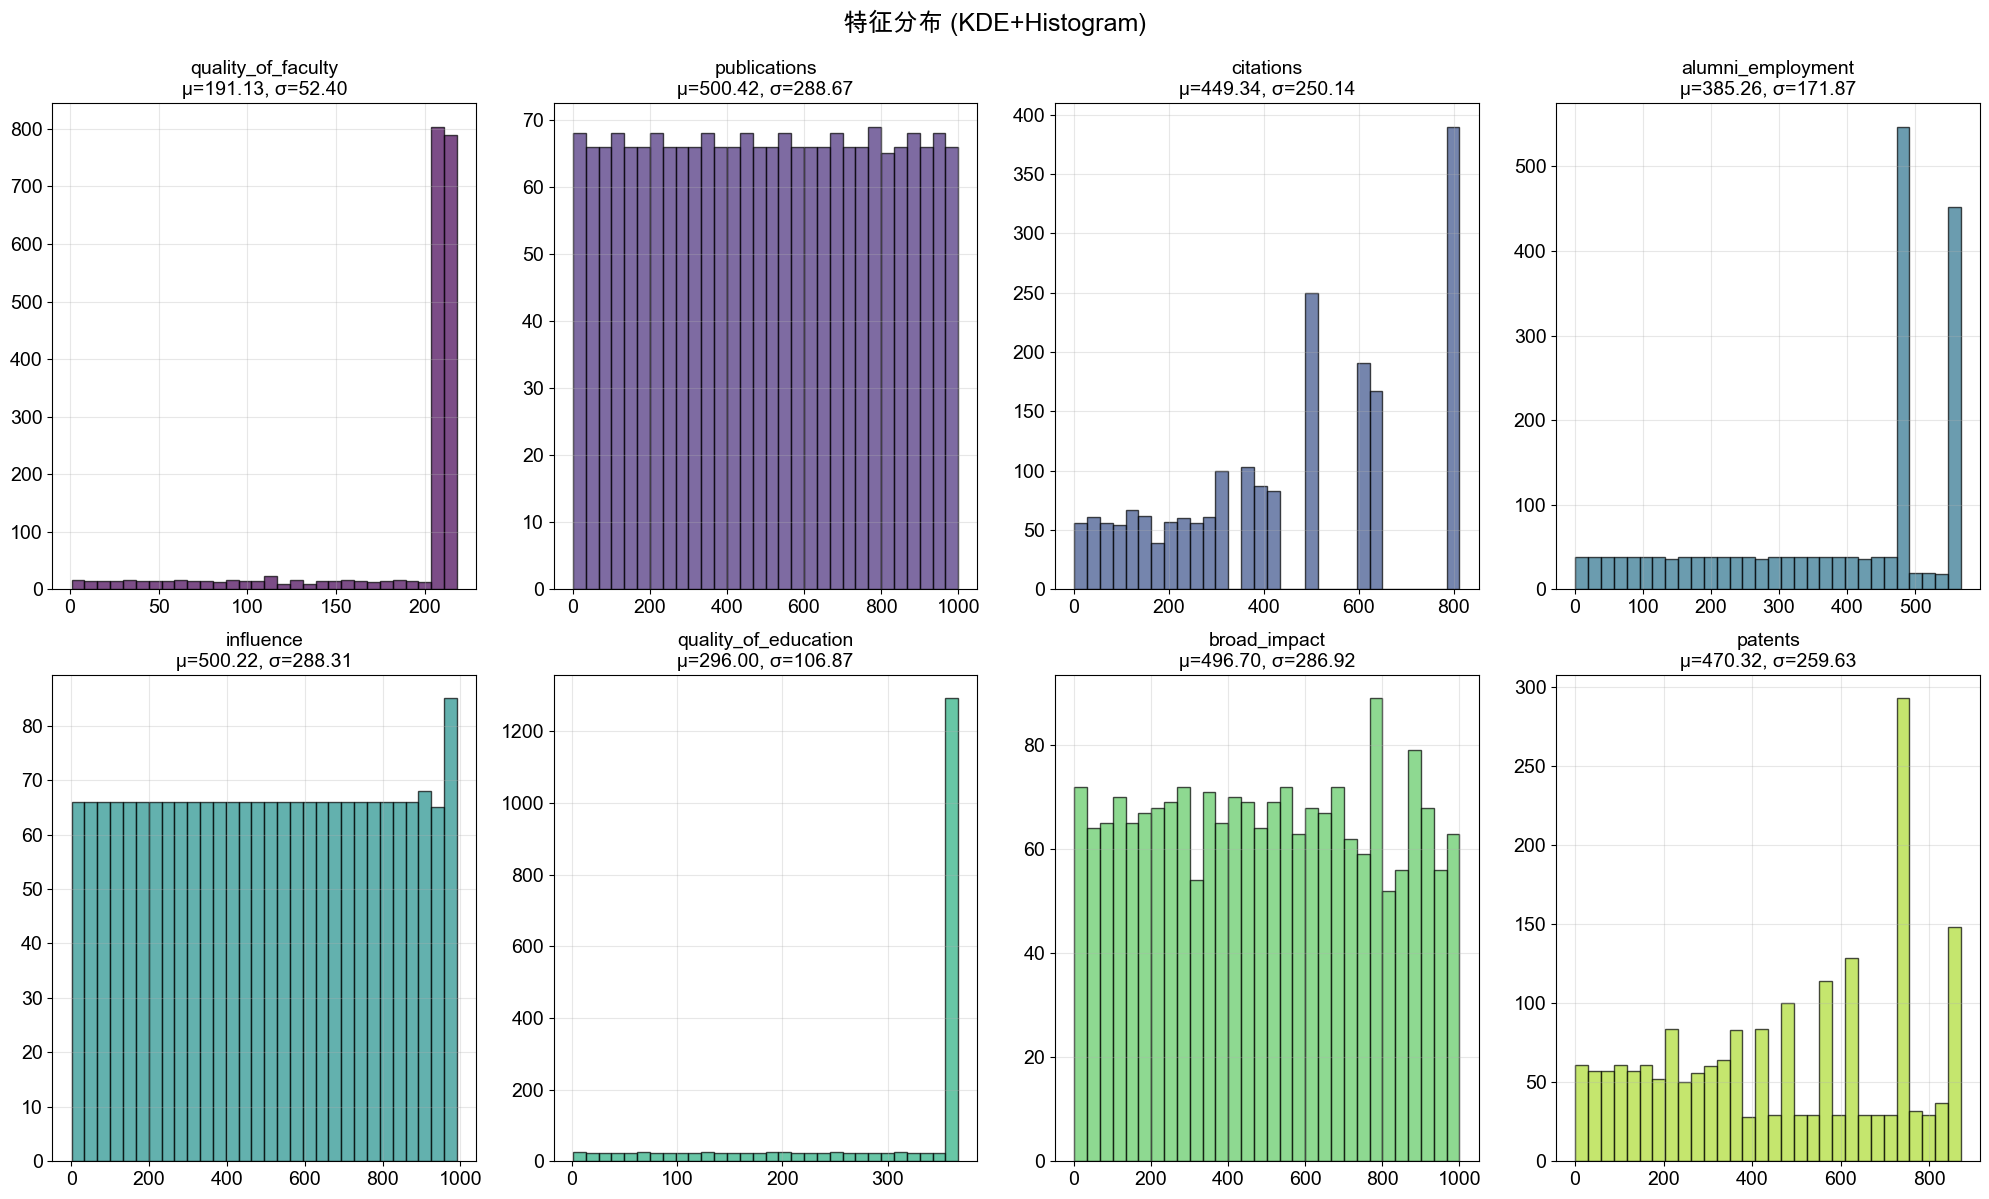

In [7]:
# Figure 2: feature distribution
print("=== 图表2: 特征分布图 ===")
fig, axes = plt.subplots(2, 4, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    ax = axes[i]
    data = data_df[col].dropna()
    ax.hist(data, bins=30, alpha=0.7, color=plt.cm.viridis(i/len(feature_cols)), edgecolor='black')
    ax.set_title(f'{col}\nμ={data.mean():.2f}, σ={data.std():.2f}', fontsize=14)
    ax.tick_params(labelsize=14)
    ax.grid(alpha=0.3)

# Hide extra subplots
for i in range(len(feature_cols), len(axes)):
    axes[i].axis('off')

plt.suptitle('特征分布 (KDE+Histogram)', fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

### Experiment notes — 15

Interpretation of results and model behavior. Inspect and engineer input features.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

=== 图表3: Q-Q plots ===


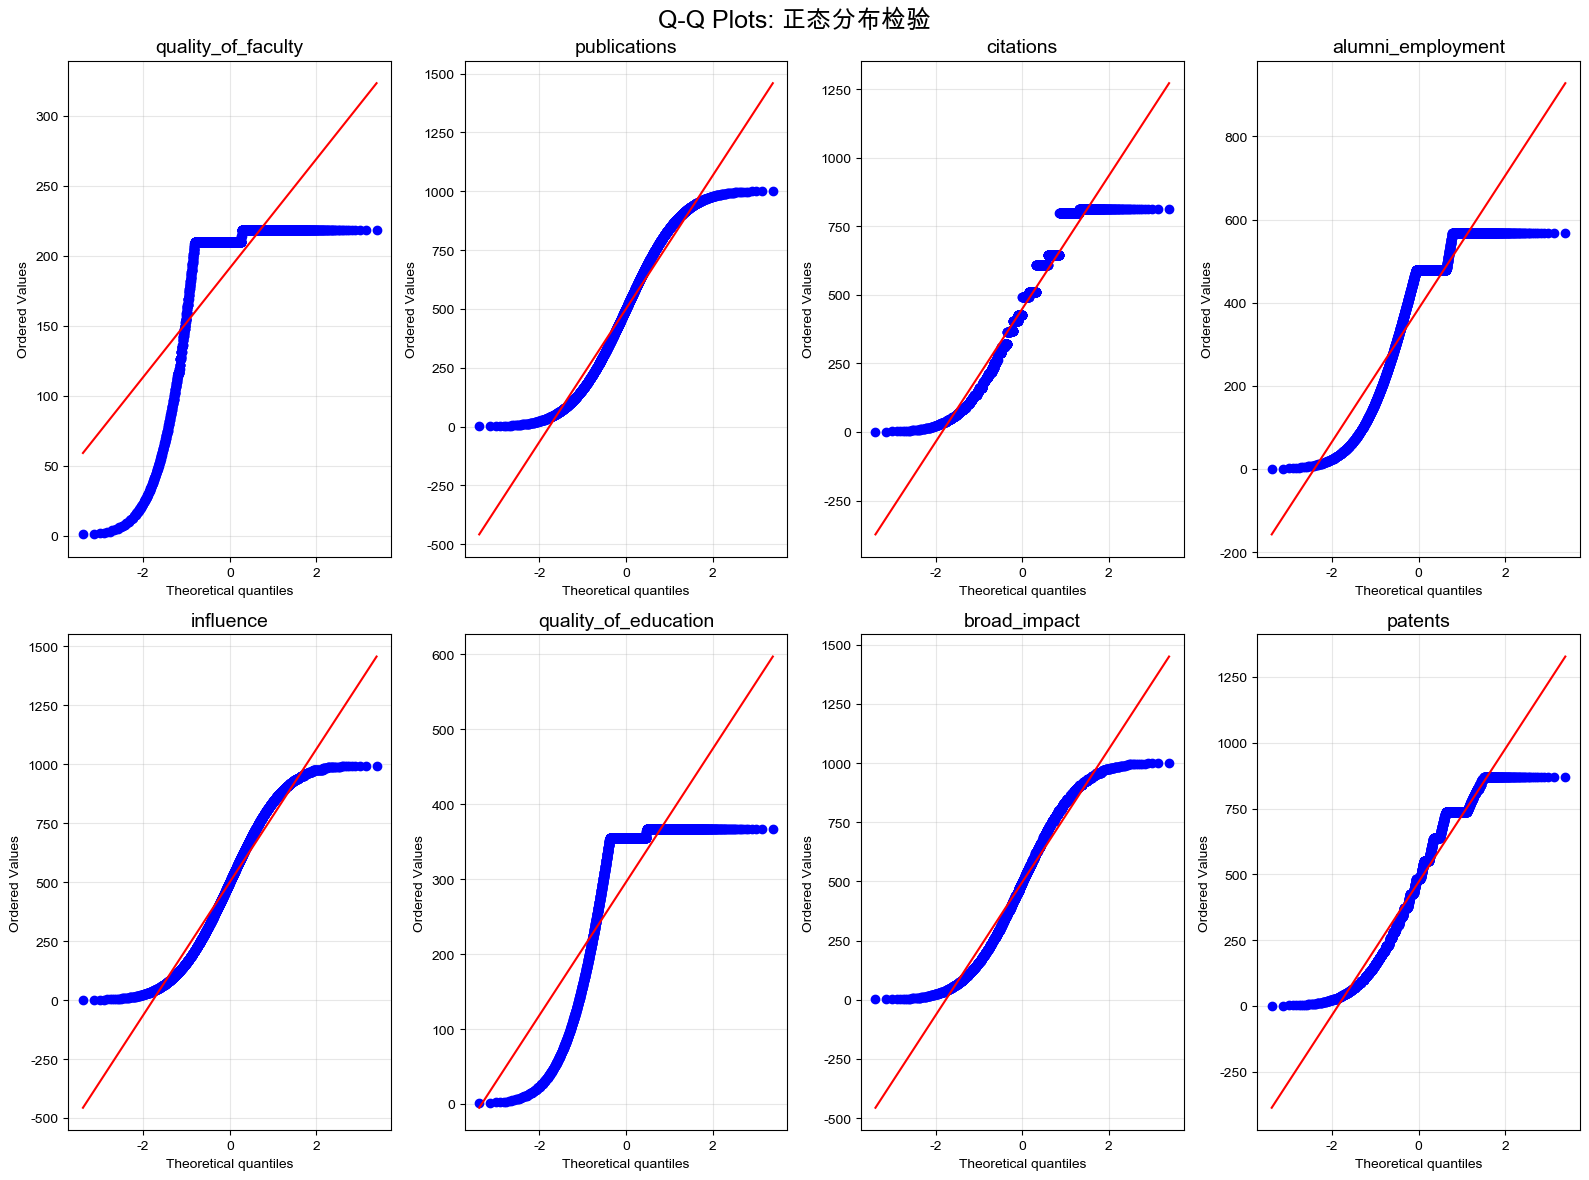

In [8]:
# Figure 3: Q-Q plot distribution
from scipy import stats

print("=== 图表3: Q-Q plots ===")
fig, axes = plt.subplots(2, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    ax = axes[i]
    data = data_df[col].dropna()
    stats.probplot(data, dist="norm", plot=ax)
    ax.set_title(f'{col}', fontsize=14, fontweight='bold')
    ax.grid(alpha=0.3)

plt.suptitle('Q-Q Plots: 正态分布检验', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

### Experiment notes — 17

Inspect and engineer input features.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

=== 图表4:相关性分析 ===


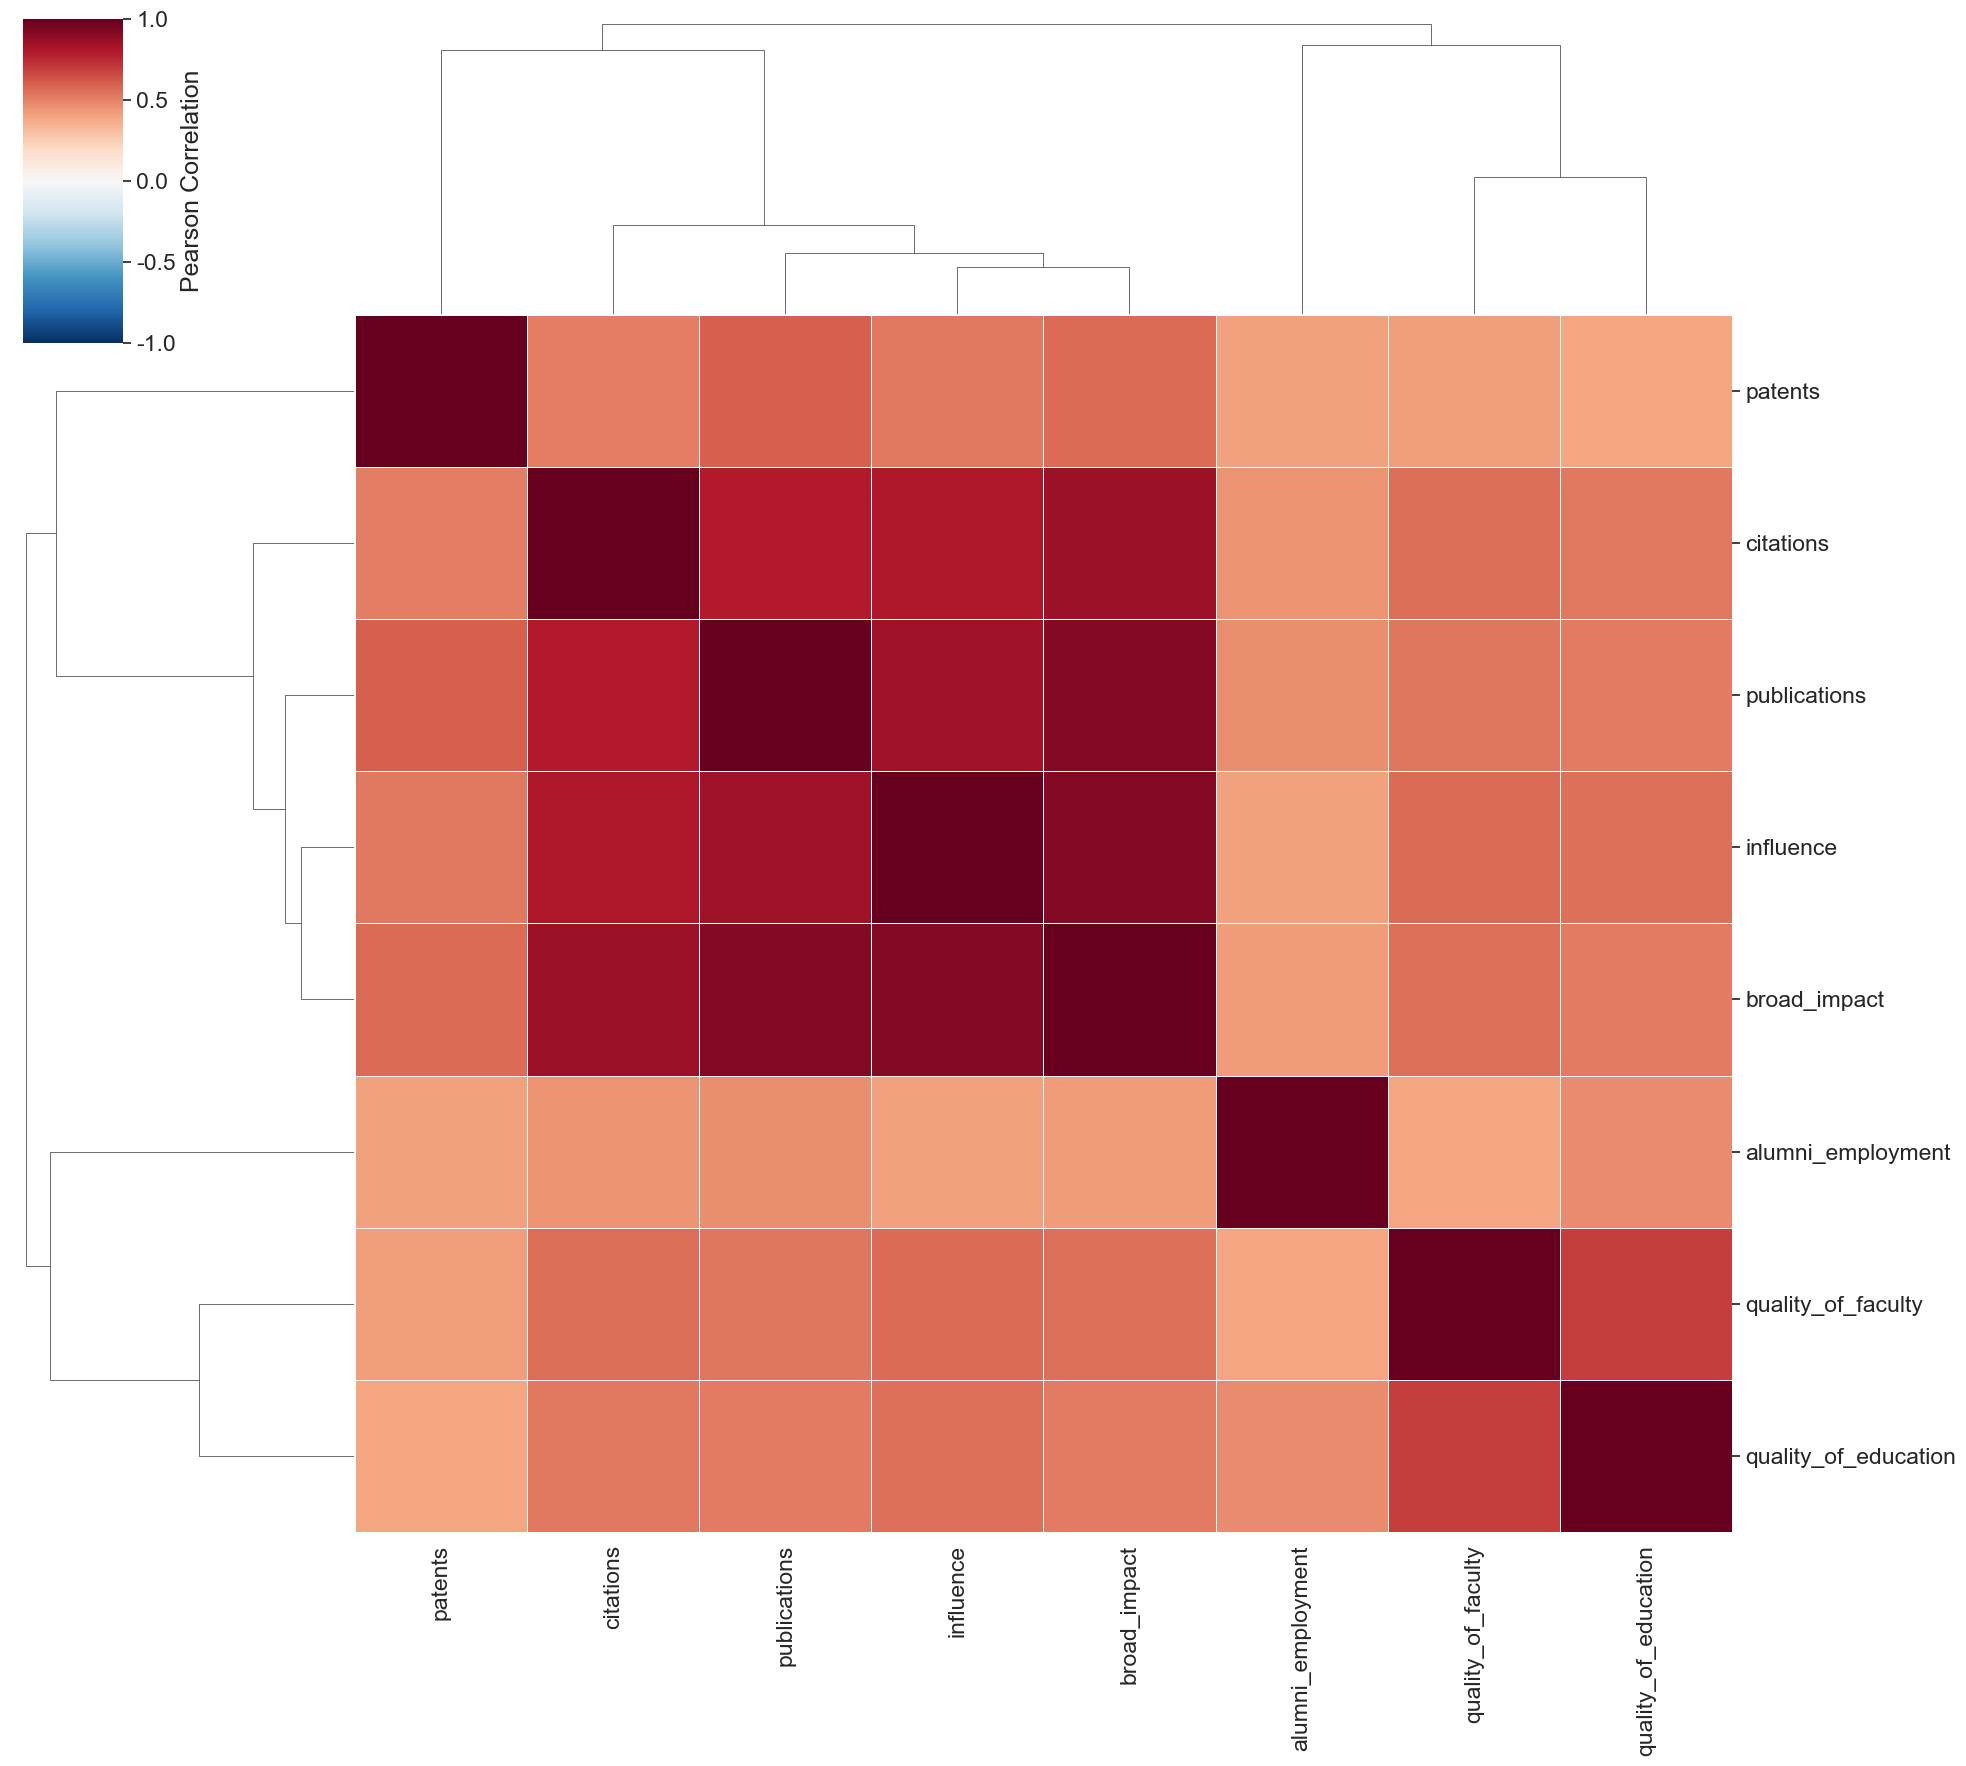

In [9]:
# Figure 4: correlation matrix
print("=== 图表4:相关性分析 ===")
# Calculate correlation
corr_matrix = data_df[feature_cols].corr()

sns.set_theme(font_scale=1.5)  # all text
g = sns.clustermap(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, 
               figsize=(20, 18), method='average', 
               linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})

plt.show()

### Experiment notes — 19

Inspect and engineer input features. Key techniques: PCA.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

=== 图表5: PCA分析 ===


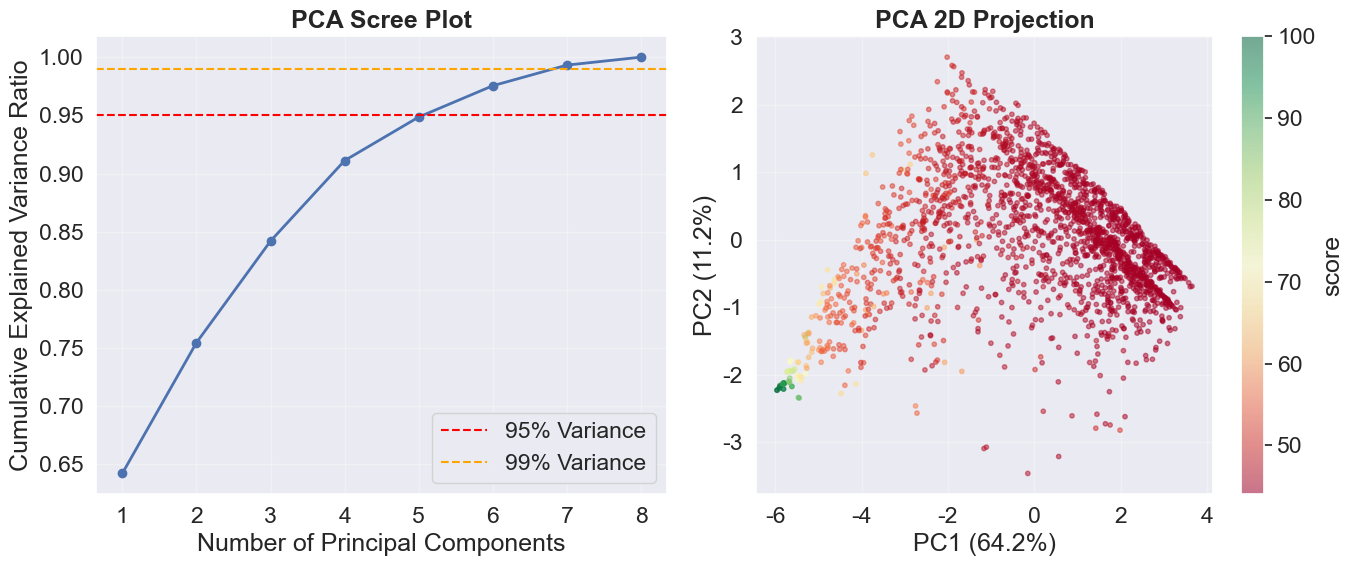


First 3 principal components explain 84.20% of variance

First 5 principal components explain 94.85% of variance


In [10]:
# Figure 5: PCA analysis

# standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_df[feature_cols].fillna(0))

# PCA
pca = PCA()
pca.fit(X_scaled)

print("=== 图表5: PCA分析 ===")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scree plot
ax = axes[0]
variance_ratio = pca.explained_variance_ratio_
cumsum_variance = np.cumsum(variance_ratio)
ax.plot(range(1, len(variance_ratio)+1), cumsum_variance, 'bo-', linewidth=2)
ax.axhline(0.95, color='red', linestyle='--', label='95% Variance')
ax.axhline(0.99, color='orange', linestyle='--', label='99% Variance')
ax.set_xlabel('Number of Principal Components')
ax.set_ylabel('Cumulative Explained Variance Ratio')
ax.set_title('PCA Scree Plot', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# Sample distribution in first 2 principal components
ax = axes[1]
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled[:10000])  # Sample 10k
if 'score' in data_df.columns:
    colors = data_df['score'].fillna(0)
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, cmap='RdYlGn', 
                         s=10, alpha=0.5)
    plt.colorbar(scatter, ax=ax, label='score')
else:
    ax.scatter(X_pca[:, 0], X_pca[:, 1], s=10, alpha=0.5)
ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})')
ax.set_title('PCA 2D Projection', fontweight='bold')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print(f"\nFirst 3 principal components explain {cumsum_variance[2]:.2%} of variance")
print(f"\nFirst 5 principal components explain {cumsum_variance[4]:.2%} of variance")

=== 图表6: 自变量与 score 的散点图（带线性拟合线） ===


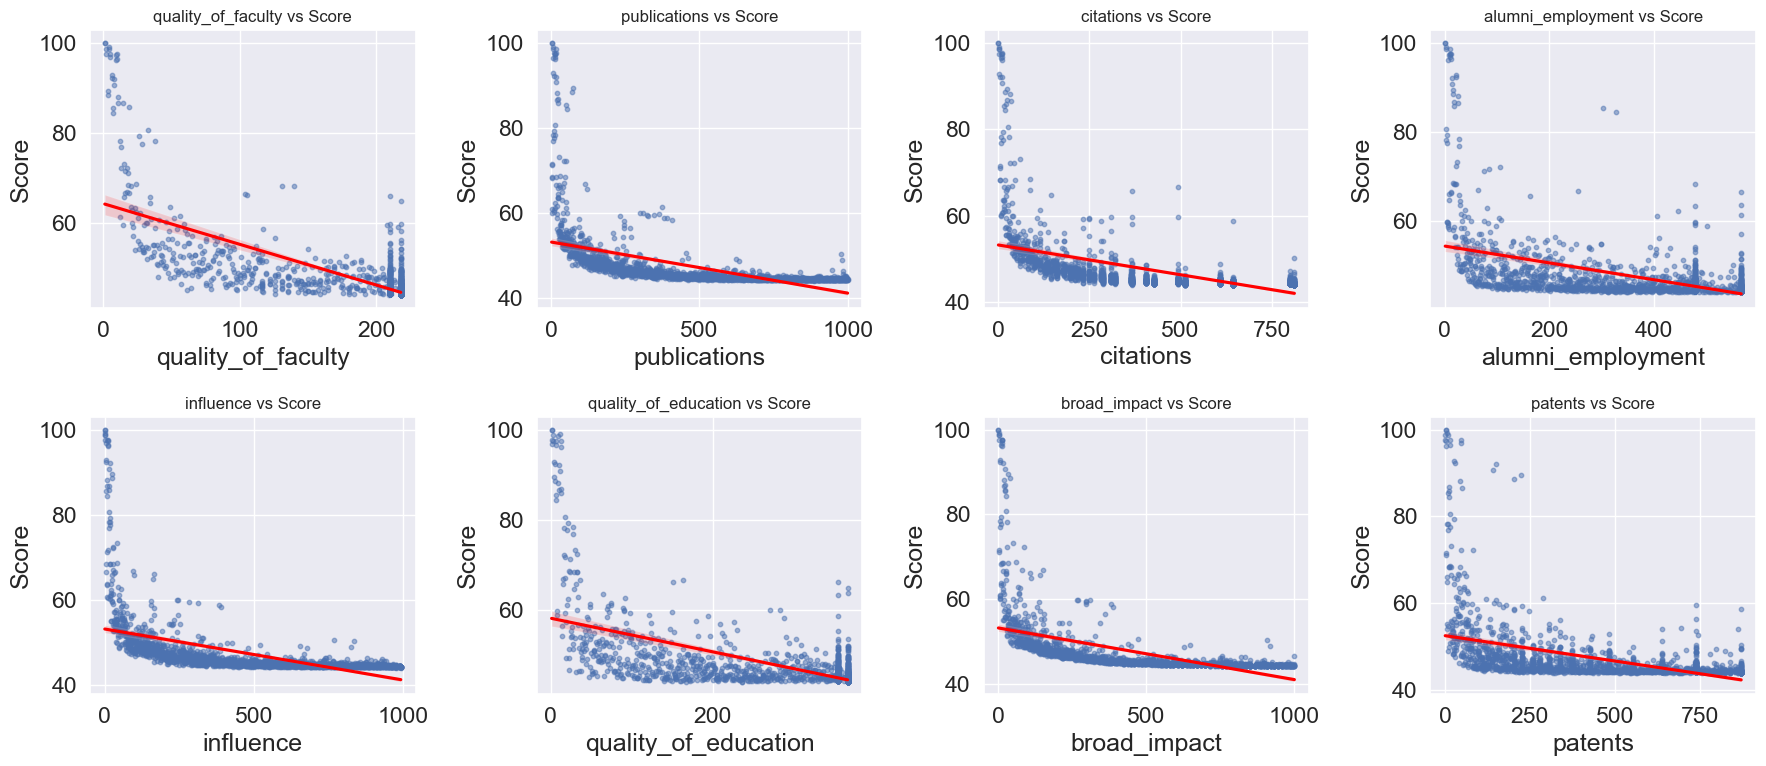

In [11]:
# Figure 6: and score plot （ fit

print("=== 图表6: 自变量与 score 的散点图（带线性拟合线） ===")

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

# loop plot plot + fit
for idx, col in enumerate(feature_cols):
    sns.regplot(x=data_df[col], y=data_df['score'], ax=axes[idx],
                scatter_kws={'alpha':0.5, 's':10},   # Implementation note
                line_kws={'color':'red'},            # fit for
                lowess=False)                         # use regression fit
    axes[idx].set_title(f'{col} vs Score', fontsize=12)
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Score')

plt.tight_layout()
plt.show()

### Experiment notes — 22

Inspect and engineer input features.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 23

Train and compare machine learning models.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [12]:
# training
all_results = []

In [13]:
# training set and validation set
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=RANDOM_SEED)
print(X.shape, Y.shape, x_train.shape, x_test.shape, y_train.shape, y_test.shape) # output data

# standardization data
# initialize standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)   # training set ：fit + transform
X_test_scaled = scaler.transform(x_test)  

(2000, 8) (2000,) (1600, 8) (400, 8) (1600,) (400,)


### Experiment notes — 26

Fit models and inspect generalization.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [14]:
# compute training set value
model_name = 'Baseline (Mean)'
y_train_mean = y_train.mean()

y_pred_mean = np.full_like(y_test, y_train_mean)
r2_mean = r2_score(y_test, y_pred_mean)
rmse_mean = root_mean_squared_error(y_test, y_pred_mean)
all_results.append({'Model': model_name, 'R2': r2_mean, 'RMSE': rmse_mean})

print("=== 基线模型: 永远预测均值 ===")
print(f"训练集均值: {y_train_mean:.3f}")
print(f"基线 R²: {r2_mean:.3f}")
print(f"基线 RMSE: {rmse_mean:.3f}")
print("\n解释: 任何RMSE < 4.193 的模型都比'什么都不做'强")
print("      任何RMSE > 4.193 的模型都比'什么都不做'差")
print("      R²为负数，反映了基线模型的局限性")

=== 基线模型: 永远预测均值 ===
训练集均值: 47.252
基线 R²: -0.051
基线 RMSE: 4.193

解释: 任何RMSE < 4.193 的模型都比'什么都不做'强
      任何RMSE > 4.193 的模型都比'什么都不做'差
      R²为负数，反映了基线模型的局限性


### Experiment notes — 28

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [15]:
# training Ridge model
import joblib

model_name = 'Ridge (alpha=5000)'
ridge = Ridge(alpha=5000, random_state=RANDOM_SEED)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

# evaluate
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = root_mean_squared_error(y_test, y_pred_ridge)
all_results.append({'Model': model_name, 'R2': r2_ridge, 'RMSE': rmse_ridge})

print("=== 线性模型1: Ridge回归 (alpha=5000.0) ===")
print(f"Ridge回归 R²: {r2_ridge:.3f}")
print(f"Ridge回归 RMSE:    {rmse_ridge:.3f}")
print(f"预测值范围: [{y_pred_ridge.min():.1f}, {y_pred_ridge.max():.1f}]")
print("\n模型评价: 1) Ridge RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_ridge:.3f}, 该模型解释了约 {r2_ridge*100:.1f}% 的方差")

=== 线性模型1: Ridge回归 (alpha=5000.0) ===
Ridge回归 R²: 0.526
Ridge回归 RMSE:    2.815
预测值范围: [43.0, 56.0]

模型评价: 1) Ridge RMSE < 4.193, 该模型强于基线模型
         2) R²=0.526, 该模型解释了约 52.6% 的方差


超参数调优: Ridge alpha
alpha=   0.1  →  R² = 0.353, RMSE = 3.289
alpha=   1.0  →  R² = 0.354, RMSE = 3.288
alpha=  10.0  →  R² = 0.358, RMSE = 3.277
alpha= 100.0  →  R² = 0.391, RMSE = 3.192
alpha=1000.0  →  R² = 0.506, RMSE = 2.874
alpha=5000.0  →  R² = 0.526, RMSE = 2.815
alpha=10000.0  →  R² = 0.452, RMSE = 3.028

=== 图表7: 不同正则化强度的对比 ===


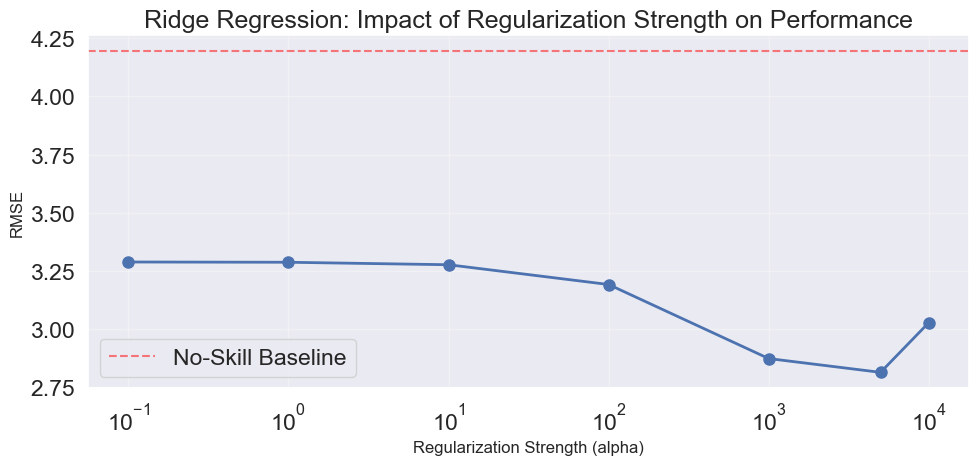


Best alpha: 5000.0


In [16]:
# different comparison
# testing different alpha value
alphas = [0.1, 1.0, 10.0, 100.0, 1000.0, 5000.0, 10000.0]
results = []

print("="*30)
print("超参数调优: Ridge alpha")
print("="*30)

for alpha in alphas:
    model = Ridge(alpha=alpha, random_state=RANDOM_SEED)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    results.append({'alpha': alpha, 'r2': r2, 'RMSE': rmse})
    print(f"alpha={alpha:6.1f}  →  R² = {r2:.3f}, RMSE = {rmse:.3f}")

# Visualization
results_df = pd.DataFrame(results)
print("\n=== 图表7: 不同正则化强度的对比 ===")
plt.figure(figsize=(10, 5))
plt.semilogx(results_df['alpha'], results_df['RMSE'], 'o-', linewidth=2, markersize=8)
plt.xlabel('Regularization Strength (alpha)', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.title('Ridge Regression: Impact of Regularization Strength on Performance', fontsize=18)
plt.grid(True, alpha=0.3)
plt.axhline(4.193, color='red', linestyle='--', alpha=0.5, label='No-Skill Baseline')
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nBest alpha: {results_df.loc[results_df['RMSE'].idxmin(), 'alpha']}")

### Experiment notes — 31

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [17]:
model_name = 'Lasso (alpha=1)'
lasso = Lasso(alpha=1, random_state=RANDOM_SEED, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)

# evaluate
r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = root_mean_squared_error(y_test, y_pred_lasso)
all_results.append({'Model': model_name, 'R2': r2_lasso, 'RMSE': rmse_lasso})

print("=== 线性模型2: Lasso回归 (alpha=1.0) ===")
print(f"Lasso回归 R²: {r2_lasso:.3f}")
print(f"Lasso回归 RMSE: {rmse_lasso:.3f}")
print(f"预测值范围: [{y_pred_lasso.min():.1f}, {y_pred_lasso.max():.1f}]")
print("\n模型评价: 1) Lasso RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_lasso:.3f}, 该模型解释了约 {r2_lasso*100:.1f}% 的方差")

=== 线性模型2: Lasso回归 (alpha=1.0) ===
Lasso回归 R²: 0.476
Lasso回归 RMSE: 2.961
预测值范围: [43.7, 62.1]

模型评价: 1) Lasso RMSE < 4.193, 该模型强于基线模型
         2) R²=0.476, 该模型解释了约 47.6% 的方差


超参数调优: Lasso alpha
alpha=   0.1  →  R² = 0.374, RMSE = 3.235  非零系数: 5
alpha=   1.0  →  R² = 0.476, RMSE = 2.961  非零系数: 5
alpha=  10.0  →  R² = -0.051, RMSE = 4.193  非零系数: 0
alpha= 100.0  →  R² = -0.051, RMSE = 4.193  非零系数: 0

=== 图表6: 不同正则化强度的对比（Lasso） ===


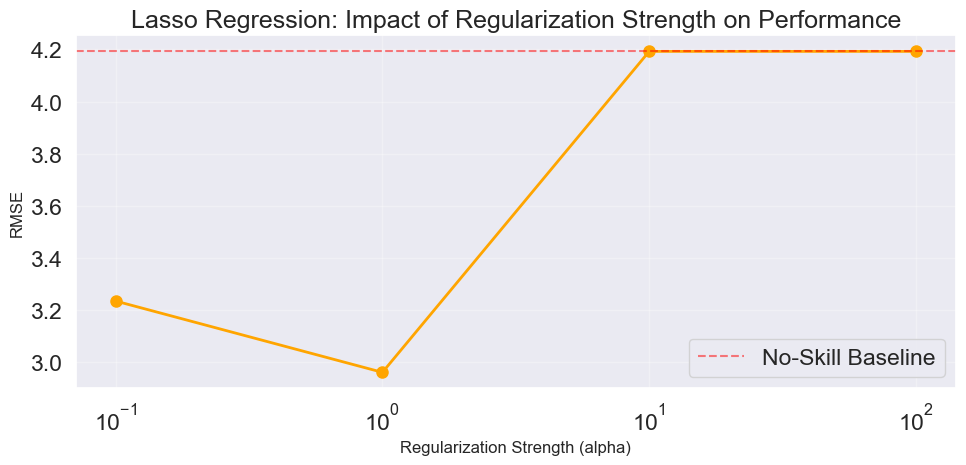


Best alpha: 1.0


In [18]:
# different comparison
alphas = [0.1, 1.0, 10.0, 100.0]
results = []

print("="*30)
print("超参数调优: Lasso alpha")
print("="*30)

for alpha in alphas:
    model = Lasso(alpha=alpha, random_state=RANDOM_SEED, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    # record
    n_nonzero = np.sum(model.coef_ != 0)
    
    results.append({'alpha': alpha, 'r2': r2, 'RMSE': rmse, 'n_nonzero': n_nonzero})
    print(f"alpha={alpha:6.1f}  →  R² = {r2:.3f}, RMSE = {rmse:.3f}  非零系数: {n_nonzero}")

# visualization
results_df = pd.DataFrame(results)
print("\n=== 图表6: 不同正则化强度的对比（Lasso） ===")
plt.figure(figsize=(10, 5))
plt.semilogx(results_df['alpha'], results_df['RMSE'], 'o-', linewidth=2, markersize=8, color='orange')
plt.xlabel('Regularization Strength (alpha)', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.title('Lasso Regression: Impact of Regularization Strength on Performance', fontsize=18)
plt.grid(True, alpha=0.3)
plt.axhline(4.193, color='red', linestyle='--', alpha=0.5, label='No-Skill Baseline')
plt.legend()
plt.tight_layout()
plt.show()

best_alpha = results_df.loc[results_df['RMSE'].idxmin(), 'alpha']
print(f"\nBest alpha: {best_alpha}")

### Experiment notes — 34

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 35

Review the implementation and results for this stage of the experiment. Key techniques: PCA.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [19]:
model_name = 'PCR (n_components=2)'
n_components_fixed = 2
pcr_pipe = make_pipeline(PCA(n_components=n_components_fixed), LinearRegression())
pcr_pipe.fit(X_train_scaled, y_train)
y_pred_pcr = pcr_pipe.predict(X_test_scaled)

r2_pcr = r2_score(y_test, y_pred_pcr)
rmse_pcr = root_mean_squared_error(y_test, y_pred_pcr)
all_results.append({'Model': model_name, 'R2': r2_pcr, 'RMSE': rmse_pcr})

print("=== 线性模型3: 主成分回归 (PCR)  n_components=2 ===")
print(f"PCR R²: {r2_pcr:.3f}")
print(f"PCR RMSE: {rmse_pcr:.3f}")
print(f"预测值范围: [{y_pred_pcr.min():.1f}, {y_pred_pcr.max():.1f}]")
print("\n模型评价: 1) PCR RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_pcr:.3f}, 该模型解释了约 {r2_pcr*100:.1f}% 的方差")

=== 线性模型3: 主成分回归 (PCR)  n_components=2 ===
PCR R²: 0.371
PCR RMSE: 3.244
预测值范围: [41.2, 64.2]

模型评价: 1) PCR RMSE < 4.193, 该模型强于基线模型
         2) R²=0.371, 该模型解释了约 37.1% 的方差


超参数调优: PCR 主成分个数
n_components=1  →  R² = 0.364, RMSE = 3.262  累计解释方差: 64.92%
n_components=2  →  R² = 0.371, RMSE = 3.244  累计解释方差: 76.11%
n_components=3  →  R² = 0.345, RMSE = 3.311  累计解释方差: 84.65%
n_components=4  →  R² = 0.351, RMSE = 3.296  累计解释方差: 91.42%
n_components=5  →  R² = 0.353, RMSE = 3.289  累计解释方差: 95.17%
n_components=6  →  R² = 0.354, RMSE = 3.286  累计解释方差: 97.69%
n_components=7  →  R² = 0.354, RMSE = 3.287  累计解释方差: 99.35%
n_components=8  →  R² = 0.353, RMSE = 3.289  累计解释方差: 100.00%

=== 图表7: 不同主成分个数的对比（PCR） ===


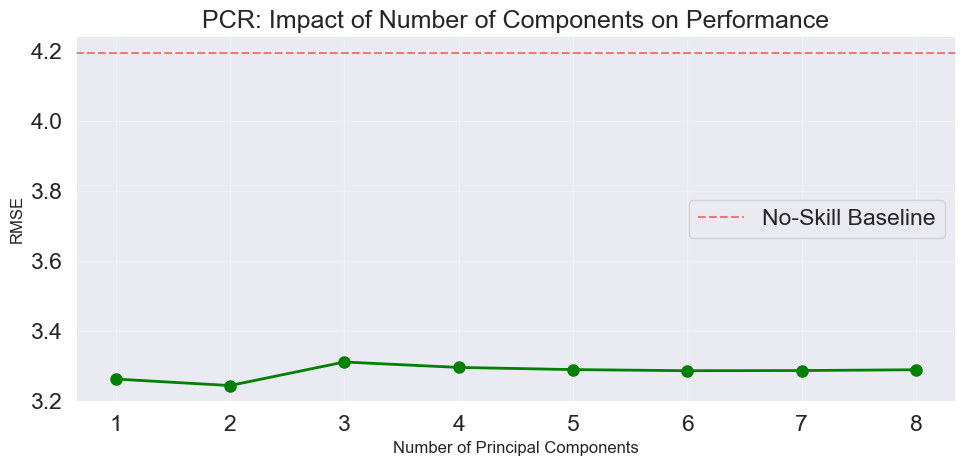


最佳主成分个数: 2


In [20]:
# different comparison
n_components_list = list(range(1, 9))  # 1 to 8（ feature total
results_pcr = []

print("="*30)
print("超参数调优: PCR 主成分个数")
print("="*30)

for k in n_components_list:
    # again create PCA fit
    pca = PCA(n_components=k)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    lr = LinearRegression()
    lr.fit(X_train_pca, y_train)
    y_pred = lr.predict(X_test_pca)
    
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    # record
    cumsum_var = np.sum(pca.explained_variance_ratio_)
    
    results_pcr.append({'n_components': k, 'r2': r2, 'RMSE': rmse, 'cum_var': cumsum_var})
    print(f"n_components={k:1d}  →  R² = {r2:.3f}, RMSE = {rmse:.3f}  累计解释方差: {cumsum_var:.2%}")

# visualization
results_df_pcr = pd.DataFrame(results_pcr)
print("\n=== 图表7: 不同主成分个数的对比（PCR） ===")
plt.figure(figsize=(10, 5))
plt.plot(results_df_pcr['n_components'], results_df_pcr['RMSE'], 'o-', linewidth=2, markersize=8, color='green')
plt.xlabel('Number of Principal Components', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.title('PCR: Impact of Number of Components on Performance', fontsize=18)
plt.grid(True, alpha=0.3)
plt.axhline(4.193, color='red', linestyle='--', alpha=0.5, label='No-Skill Baseline')
plt.xticks(n_components_list)
plt.legend()
plt.tight_layout()
plt.show()

best_k = results_df_pcr.loc[results_df_pcr['RMSE'].idxmin(), 'n_components']
print(f"\n最佳主成分个数: {best_k}")

### Experiment notes — 38

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [21]:
# define
def log_transform(x):
    """对数变换，处理零值：log(1+x)"""
    return np.log1p(x)

def sqrt_transform(x):
    """平方根变换"""
    return np.sqrt(x)

def reciprocal_transform(x, epsilon=1e-3):
    """倒数变换，避免除以零：1/(x+epsilon)"""
    return 1 / (x + epsilon)

def power_transform(x, power=0.5):
    """幂变换，可指定指数，默认0.5即平方根"""
    return np.power(x, power)

# define compare table （ each one (, function )
transforms = [
    ('None', None),                # feature
    ('Log', log_transform),
    ('Sqrt', sqrt_transform),
    ('Reciprocal', reciprocal_transform),
    ('Power(0.3)', lambda x: power_transform(x, 0.3)),
    ('Power(0.7)', lambda x: power_transform(x, 0.7)),
]

In [22]:
# use Ridge model (alpha)
model_name = 'Log + RidgeCV'

# define RidgeCV alpha （ adjust
alphas = np.logspace(1, 6, 50)  # 10^1 to 10^6，50

# use RidgeCV best alpha
transform_name, transform_func = ('Log', log_transform)
if transform_func is None:
    X_train_trans = x_train.copy()
    X_test_trans = x_test.copy()
else:
    X_train_trans = transform_func(x_train)
    X_test_trans = transform_func(x_test)

# standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_trans)
X_test_scaled = scaler.transform(X_test_trans)

# use RidgeCV select best alpha
ridgecv = RidgeCV(alphas=alphas, cv=5, scoring='neg_root_mean_squared_error')
ridgecv.fit(X_train_scaled, y_train)
y_pred = ridgecv.predict(X_test_scaled)

r2_logRidge = r2_score(y_test, y_pred)
rmse_logRidge = root_mean_squared_error(y_test, y_pred)
all_results.append({'Model': model_name, 'R2': r2_logRidge, 'RMSE': rmse_logRidge})

print("=== 非线性变换: 对数变换 + RidgeCV (自动选alpha) ===")
print(f"最佳 alpha: {ridgecv.alpha_:.2f}")
print(f"R²: {r2_logRidge:.3f}")
print(f"RMSE: {rmse_logRidge:.3f}")
print(f"预测值范围: [{y_pred.min():.1f}, {y_pred.max():.1f}]")
print("\n模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_logRidge:.3f}, 该模型解释了约 {r2_logRidge*100:.1f}% 的方差")

=== 非线性变换: 对数变换 + RidgeCV (自动选alpha) ===
最佳 alpha: 25.60
R²: 0.701
RMSE: 2.236
预测值范围: [42.5, 78.4]

模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型
         2) R²=0.701, 该模型解释了约 70.1% 的方差



不同特征变换的 Ridge 性能对比
None         → 最佳alpha=   51.79, R² = 0.375, RMSE = 3.234
Log          → 最佳alpha=   25.60, R² = 0.701, RMSE = 2.236
Sqrt         → 最佳alpha=   32.37, R² = 0.479, RMSE = 2.952
Reciprocal   → 最佳alpha= 1757.51, R² = 0.320, RMSE = 3.374
Power(0.3)   → 最佳alpha=   25.60, R² = 0.554, RMSE = 2.730
Power(0.7)   → 最佳alpha=   40.95, R² = 0.426, RMSE = 3.097


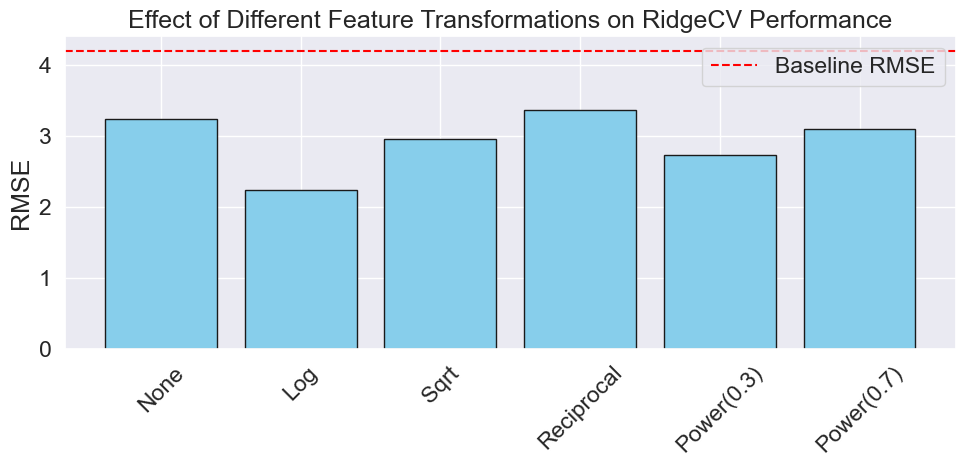


最佳变换: Log, RMSE = 2.236


In [23]:
# loop compare different （ use RidgeCV
print("\n" + "="*30)
print("不同特征变换的 Ridge 性能对比")
print("="*30)

# save results
results = []

for name, func in transforms:
    # Implementation note
    if func is None:
        X_train_t = x_train.copy()
        X_test_t = x_test.copy()
    else:
        X_train_t = func(x_train)
        X_test_t = func(x_test)
    
    # standardization
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_t)
    X_test_scaled = scaler.transform(X_test_t)
    
    # use RidgeCV select best alpha
    ridgecv = RidgeCV(alphas=alphas, cv=5, scoring='neg_root_mean_squared_error')
    ridgecv.fit(X_train_scaled, y_train)
    y_pred = ridgecv.predict(X_test_scaled)
    
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    results.append({'transform': name, 'r2': r2, 'RMSE': rmse, 'best_alpha': ridgecv.alpha_})
    print(f"{name:12s} → 最佳alpha={ridgecv.alpha_:8.2f}, R² = {r2:.3f}, RMSE = {rmse:.3f}")

# visualization comparison
results_df = pd.DataFrame(results)
plt.figure(figsize=(10, 5))
bars = plt.bar(results_df['transform'], results_df['RMSE'], color='skyblue', edgecolor='k')
plt.axhline(4.193, color='red', linestyle='--', label='Baseline RMSE')
plt.ylabel('RMSE')
plt.title('Effect of Different Feature Transformations on RidgeCV Performance')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

best_transform = results_df.loc[results_df['RMSE'].idxmin(), 'transform']
print(f"\n最佳变换: {best_transform}, RMSE = {results_df['RMSE'].min():.3f}")

### Experiment notes — 42

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [24]:
# take training set and test set region value
region_train = data_df.loc[x_train.index, 'region']
region_test = data_df.loc[x_test.index, 'region']

In [25]:
x_train_log = np.log1p(x_train)   # x_train feature take log(1+x)
x_test_log = np.log1p(x_test)

# region encoding
region_train_encoded = pd.get_dummies(region_train, prefix='region', drop_first=True)
region_test_encoded = pd.get_dummies(region_test, prefix='region', drop_first=True)

# test set and training set one （ test set class
region_test_encoded = region_test_encoded.reindex(columns=region_train_encoded.columns, fill_value=0)

In [26]:
# merge feature and
X_train_combined = pd.concat([x_train_log, region_train_encoded], axis=1)
X_test_combined = pd.concat([x_test_log, region_test_encoded], axis=1)

# standardization merge feature matrix （ class standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_combined)
X_test_scaled = scaler.transform(X_test_combined)

In [27]:
model_name = 'Log+RidgeCV+Region'

alphas = np.logspace(1, 6, 50)  # 10^1 to 10^6
ridgecv_region = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridgecv_region.fit(X_train_scaled, y_train)

y_pred_region = ridgecv_region.predict(X_test_scaled)
r2_region = r2_score(y_test, y_pred_region)
rmse_region = root_mean_squared_error(y_test, y_pred_region)
all_results.append({'Model': model_name, 'R2': r2_region, 'RMSE': rmse_region})

print("=== 加入 region 后的 log+RidgeCV 模型 ===")
print(f"最佳 alpha: {ridgecv_region.alpha_:.2f}")
print(f"R²: {r2_region:.3f}")
print(f"RMSE: {rmse_region:.3f}")
print(f"预测值范围: [{y_pred.min():.1f}, {y_pred.max():.1f}]")
print("\n模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_region:.3f}, 该模型解释了约 {r2_region*100:.1f}% 的方差")

=== 加入 region 后的 log+RidgeCV 模型 ===
最佳 alpha: 16.00
R²: 0.697
RMSE: 2.252
预测值范围: [41.9, 68.7]

模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型
         2) R²=0.697, 该模型解释了约 69.7% 的方差


### Experiment notes — 47

Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [28]:
print(f"\n不加 region 的 RMSE: {rmse_logRidge:.3f}")
print(f"加入 region 后的 RMSE: {rmse_region:.3f}")
improvement = (rmse_logRidge - rmse_region) / rmse_logRidge * 100
print(f"RMSE 下降: {improvement:.1f}%\n")


不加 region 的 RMSE: 2.236
加入 region 后的 RMSE: 2.252
RMSE 下降: -0.7%



### Experiment notes — 49

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 50

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [29]:
# data
# feature
numeric_cols = feature_cols + ['score']

# institution grouped ， take value value ， retain region（ value
df_agg = data_df.groupby('institution').agg({
    **{col: 'mean' for col in numeric_cols},
    'region': 'first'  # take first
}).reset_index()

print(f"聚合前样本数: {len(data_df)}，聚合后样本数: {len(df_agg)}")

聚合前样本数: 2000，聚合后样本数: 1023


In [30]:
# again define feature and
feature_cols_agg = feature_cols.copy()  # 8 value feature
categorical_col = 'region'

X_agg = df_agg[feature_cols_agg]
y_agg = df_agg['score']
region_agg = df_agg[categorical_col]

# split training set and test set
X_train_agg, X_test_agg, y_train_agg, y_test_agg, region_train_agg, region_test_agg = train_test_split(
    X_agg, y_agg, region_agg, test_size=0.2, random_state=RANDOM_SEED
)

In [31]:
# feature take
X_train_log = np.log1p(X_train_agg)
X_test_log = np.log1p(X_test_agg)

# region encoding
region_train_encoded = pd.get_dummies(region_train_agg, prefix='region', drop_first=True)
region_test_encoded = pd.get_dummies(region_test_agg, prefix='region', drop_first=True)
region_test_encoded = region_test_encoded.reindex(columns=region_train_encoded.columns, fill_value=0)

# merge feature
X_train_combined = pd.concat([X_train_log, region_train_encoded], axis=1)
X_test_combined = pd.concat([X_test_log, region_test_encoded], axis=1)

# standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_combined)
X_test_scaled = scaler.transform(X_test_combined)

In [32]:
model_name = 'Aggregated + log + RidgeCV + Region'

# RidgeCV hyperparameter tuning
alphas = np.logspace(1, 6, 50)
ridge_agg = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridge_agg.fit(X_train_scaled, y_train_agg)

# prediction and evaluate
y_pred_agg = ridge_agg.predict(X_test_scaled)
r2_agg = r2_score(y_test_agg, y_pred_agg)
rmse_agg = root_mean_squared_error(y_test_agg, y_pred_agg)
all_results.append({'Model': model_name, 'R2': r2_agg, 'RMSE': rmse_agg})

print("=== 聚合数据后的 log+RidgeCV+region 模型 ===")
print(f"最佳 alpha: {ridge_agg.alpha_:.2f}")
print(f"R²: {r2_agg:.3f}")
print(f"RMSE: {rmse_agg:.3f}")
print("模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型")
print(f"         2) R²={r2_agg:.3f}, 该模型解释了约 {r2_agg*100:.1f}% 的方差")

print(f"\n不加 region 的 RMSE: {rmse_logRidge:.3f}")
print(f"加入 region 后的 RMSE: {rmse_region:.3f}")
print(f"按年份聚合且加入 region 后的 RMSE: {rmse_agg:.3f}")
improvement = (rmse_region - rmse_agg) / rmse_region * 100
print(f"RMSE 下降: {improvement:.1f}%\n")

=== 聚合数据后的 log+RidgeCV+region 模型 ===
最佳 alpha: 16.00
R²: 0.884
RMSE: 3.278
模型评价: 1) Log Ridge RMSE < 4.193, 该模型强于基线模型
         2) R²=0.884, 该模型解释了约 88.4% 的方差

不加 region 的 RMSE: 2.236
加入 region 后的 RMSE: 2.252
按年份聚合且加入 region 后的 RMSE: 3.278
RMSE 下降: -45.6%



### Experiment notes — 55

Fit models and inspect generalization.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 56

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [33]:
results_summary = pd.DataFrame(all_results)

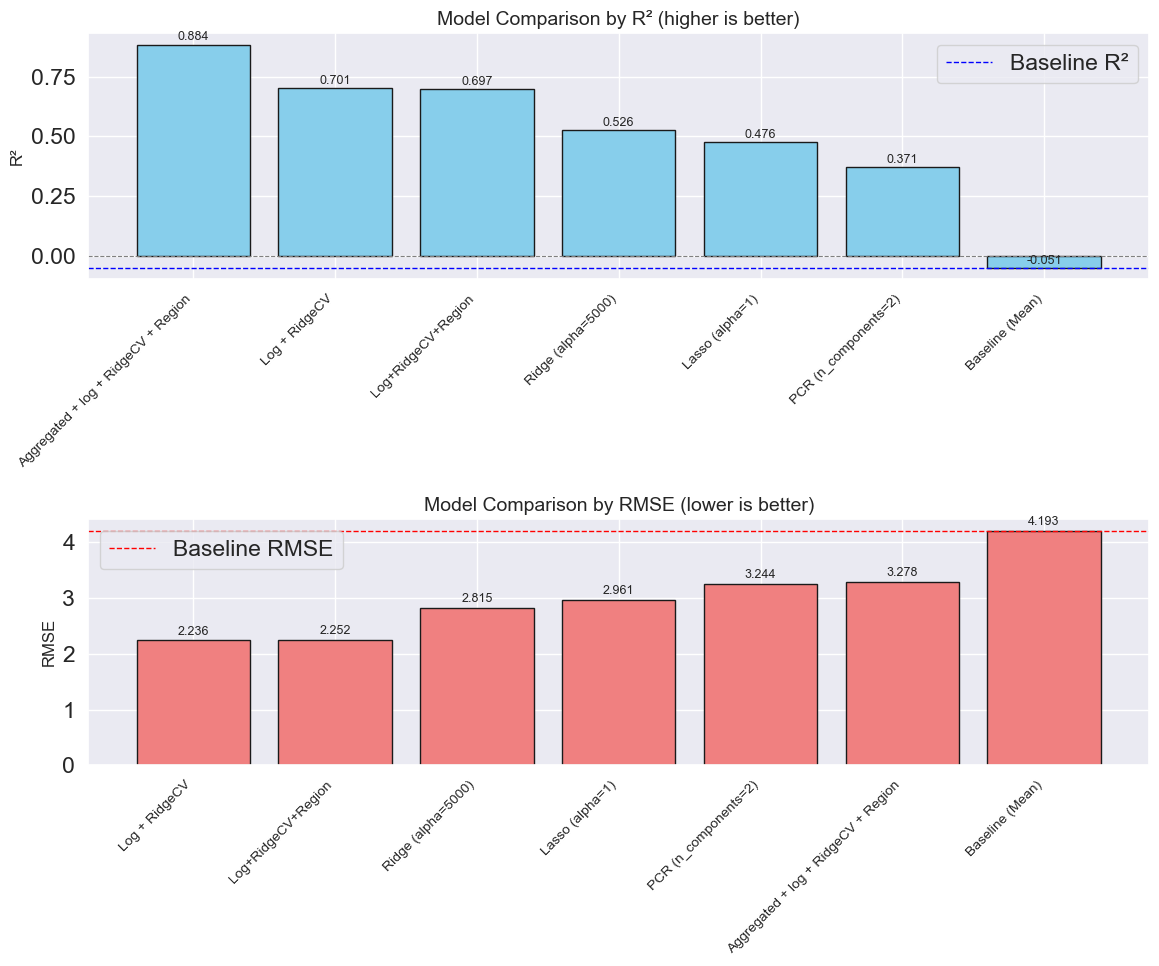

In [34]:
# R² sort
sorted_by_r2 = results_summary.sort_values('R2', ascending=False).reset_index(drop=True)
# RMSE sort
sorted_by_rmse = results_summary.sort_values('RMSE', ascending=True).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# plot ：R² plot
bars1 = ax1.bar(sorted_by_r2['Model'], sorted_by_r2['R2'], color='skyblue', edgecolor='k')
ax1.set_ylabel('R²', fontsize=12)
ax1.set_title('Model Comparison by R² (higher is better)', fontsize=14)
# x and label
ax1.set_xticks(range(len(sorted_by_r2['Model'])))
ax1.set_xticklabels(sorted_by_r2['Model'], rotation=45, ha='right', fontsize=10)
ax1.axhline(0, color='gray', linestyle='--', linewidth=0.8)
# value
for bar, val in zip(bars1, sorted_by_r2['R2']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{val:.3f}',
             ha='center', va='bottom', fontsize=9)

# plot ：RMSE plot
bars2 = ax2.bar(sorted_by_rmse['Model'], sorted_by_rmse['RMSE'], color='lightcoral', edgecolor='k')
ax2.set_ylabel('RMSE', fontsize=12)
ax2.set_title('Model Comparison by RMSE (lower is better)', fontsize=14)
# x and label
ax2.set_xticks(range(len(sorted_by_rmse['Model'])))
ax2.set_xticklabels(sorted_by_rmse['Model'], rotation=45, ha='right', fontsize=10)
# value
for bar, val in zip(bars2, sorted_by_rmse['RMSE']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{val:.3f}',
             ha='center', va='bottom', fontsize=9)

# Implementation note
ax1.axhline(-0.051, color='blue', linestyle='--', linewidth=1, label='Baseline R²')
ax1.legend()
ax2.axhline(4.193, color='red', linestyle='--', linewidth=1, label='Baseline RMSE')
ax2.legend()

plt.tight_layout()
plt.show()

In [35]:
best_model_r2 = sorted_by_r2.iloc[0]['Model']
best_r2 = sorted_by_r2.iloc[0]['R2']
best_model_rmse = sorted_by_rmse.iloc[0]['Model']
best_rmse = sorted_by_rmse.iloc[0]['RMSE']

print("="*50)
print("模型性能总结")
print("="*50)
print(f"最佳模型（按 R²）: {best_model_r2}  (R² = {best_r2:.3f})")
print(f"最佳模型（按 RMSE）: {best_model_rmse}  (RMSE = {best_rmse:.3f})")

# one ， for final model ； select （RMSE
if best_model_r2 == best_model_rmse:
    print(f"\n🎯 推荐最终模型: {best_model_r2}")
else:
    print("\n📌 注：R² 和 RMSE 最佳模型不一致，建议结合业务需求选择。")
    print("   - 若目标是 精确预测 ，优先选择 RMSE 最小的模型")
    print("   - 若更关注解释 影响因素 ，优先选择 R² 最大的模型\n")

模型性能总结
最佳模型（按 R²）: Aggregated + log + RidgeCV + Region  (R² = 0.884)
最佳模型（按 RMSE）: Log + RidgeCV  (RMSE = 2.236)

📌 注：R² 和 RMSE 最佳模型不一致，建议结合业务需求选择。
   - 若目标是 精确预测 ，优先选择 RMSE 最小的模型
   - 若更关注解释 影响因素 ，优先选择 R² 最大的模型



### Experiment notes — 60

Review the implementation and results for this stage of the experiment. Key techniques: RMSE, R².

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*